# Ensemble Stacking IDS — thống kê và kết quả thực nghiệm

Notebook tổng hợp các artifact thật đã lưu của CIC-IDS2017 và InSDN. Mặc định **Run All chỉ đọc dữ liệu và vẽ biểu đồ**; không train lại, không ghi đè model và không đọc toàn bộ CSV gốc.

Logic xử lý/huấn luyện nằm trong `src/*.py`. Notebook dùng để xem theo cell, đối chiếu, viết báo cáo và thuyết trình. Các output đã lưu là một snapshot; khi có lượt mới, đổi `RUN` rồi Restart Kernel → Run All → Save.

**Cài notebook:** `python -m pip install -r requirements-notebook.in` bằng Python của `.venv`, rồi chọn kernel `.venv` trong trình mở notebook. Dữ liệu/model gốc không được đưa vào Git; bản notebook đã lưu output vẫn xem được khi chưa có các artifact local, nhưng chạy lại cần có chúng.


In [1]:
%matplotlib inline
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, SVG

cwd = Path.cwd()
ROOT = next((p.resolve() for p in [cwd, cwd / 'network-stacking-ids', *cwd.parents]
             if (p / 'src/train.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook trong thư mục project hoặc notebooks/.')
RUN = ROOT / 'experiments' / 'completion-20261110'  # Chọn thư mục artifact ở đây.
SEED = 42  # Seed dùng cho confusion matrix và kiểm tra protocol.
if not (RUN / 'summary/all_seeds.csv').is_file():
    raise FileNotFoundError(f'Chưa có artifact tại {RUN}. Chạy thí nghiệm trước hoặc đổi RUN.')
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'font.size': 10})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 12)
print('Python:', sys.version.split()[0], '| Kernel:', Path(sys.prefix).name)
print('Artifact:', RUN.relative_to(ROOT), '| Matrix seed:', SEED)


Python: 3.14.6 | Kernel: .venv
Artifact: experiments\completion-20261110 | Matrix seed: 42


## 1. Nhãn và phân bố dữ liệu gốc

Số đếm dưới đây đọc từ `eda.json`, đã đếm trên toàn bộ CSV gốc. Nhãn tấn công vẫn được trình bày riêng theo từng dataset; không coi tên lớp hai bộ là cùng một taxonomy. Trục biểu đồ dùng log để nhìn thấy cả lớp hiếm.


,dataset,label,rows
0,CIC-IDS2017,BENIGN,2273097
1,CIC-IDS2017,DDoS,128027
2,CIC-IDS2017,PortScan,158930
3,CIC-IDS2017,Bot,1966
4,CIC-IDS2017,Infiltration,36
5,CIC-IDS2017,Web Attack � Brute Force,1507
6,CIC-IDS2017,Web Attack � XSS,652
7,CIC-IDS2017,Web Attack � Sql Injection,21
8,CIC-IDS2017,FTP-Patator,7938
9,CIC-IDS2017,SSH-Patator,5897


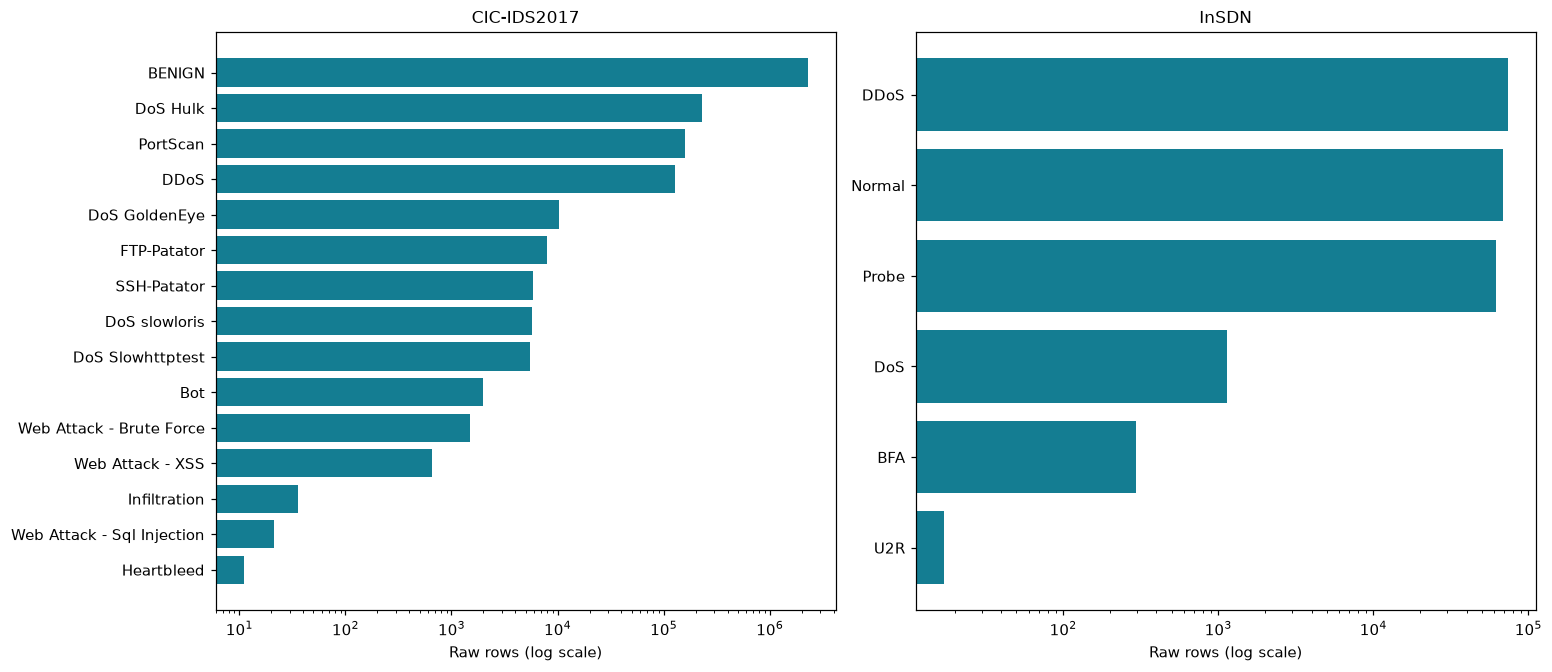

In [2]:
eda = {name: read_json(RUN / folder / 'eda.json')
       for name, folder in [('CIC-IDS2017', 'eda-cic'), ('InSDN', 'eda-insdn')]}
raw_counts = pd.DataFrame([{'dataset': name, 'label': label, 'rows': count}
                          for name, info in eda.items() for label, count in info['raw_class_counts'].items()])
display(raw_counts)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout='constrained')
for ax, (name, info) in zip(axes, eda.items()):
    counts = pd.Series(info['raw_class_counts']).sort_values()
    ax.barh([str(x).replace('\ufffd', '-') for x in counts.index], counts.values, color='#147d92')
    ax.set(xscale='log', xlabel='Raw rows (log scale)', title=name)
plt.show()


## 2. Cleanup và mẫu EDA

EDA giới hạn theo **nhãn gốc**; huấn luyện M1/M2/M3 giới hạn theo **nhãn nhị phân**. Số hàng hai loại mẫu vì vậy khác nhau. Duplicate/conflict dưới đây chỉ tính trong mẫu, không phải tỷ lệ trùng toàn corpus. Class cap trước chia tập thay đổi prevalence của test.


In [3]:
cleanup = pd.DataFrame([{
    'dataset': name, 'raw_rows': sum(info['raw_class_counts'].values()),
    'eda_sample_rows': sum(info['sample_class_counts'].values()),
    'duplicates_removed_in_sample': info['sample_duplicate_rows_removed'],
    'conflicts_removed_in_sample': info['sample_conflicting_rows_removed'],
    'excluded_classes': str(info['excluded_classes_below_minimum']),
    'missing_or_nonfinite_selected_features': sum(info['raw_missing_or_nonfinite'].values())
} for name, info in eda.items()])
display(cleanup)


,dataset,raw_rows,eda_sample_rows,duplicates_removed_in_sample,conflicts_removed_in_sample,excluded_classes,missing_or_nonfinite_selected_features
0,CIC-IDS2017,2830743,19561,2466,155,{'Heartbleed': 11},0
1,InSDN,205167,5482,1975,0,{},0


## 3. Phân phối feature và correlation

Các ảnh đọc trực tiếp từ output EDA đã tạo, không tính lại từ CSV gốc. Correlation và phân phối dựa trên mẫu giới hạn; không dùng correlation test để chọn feature rồi tiếp tục coi đó là test cuối.


### CIC-IDS2017

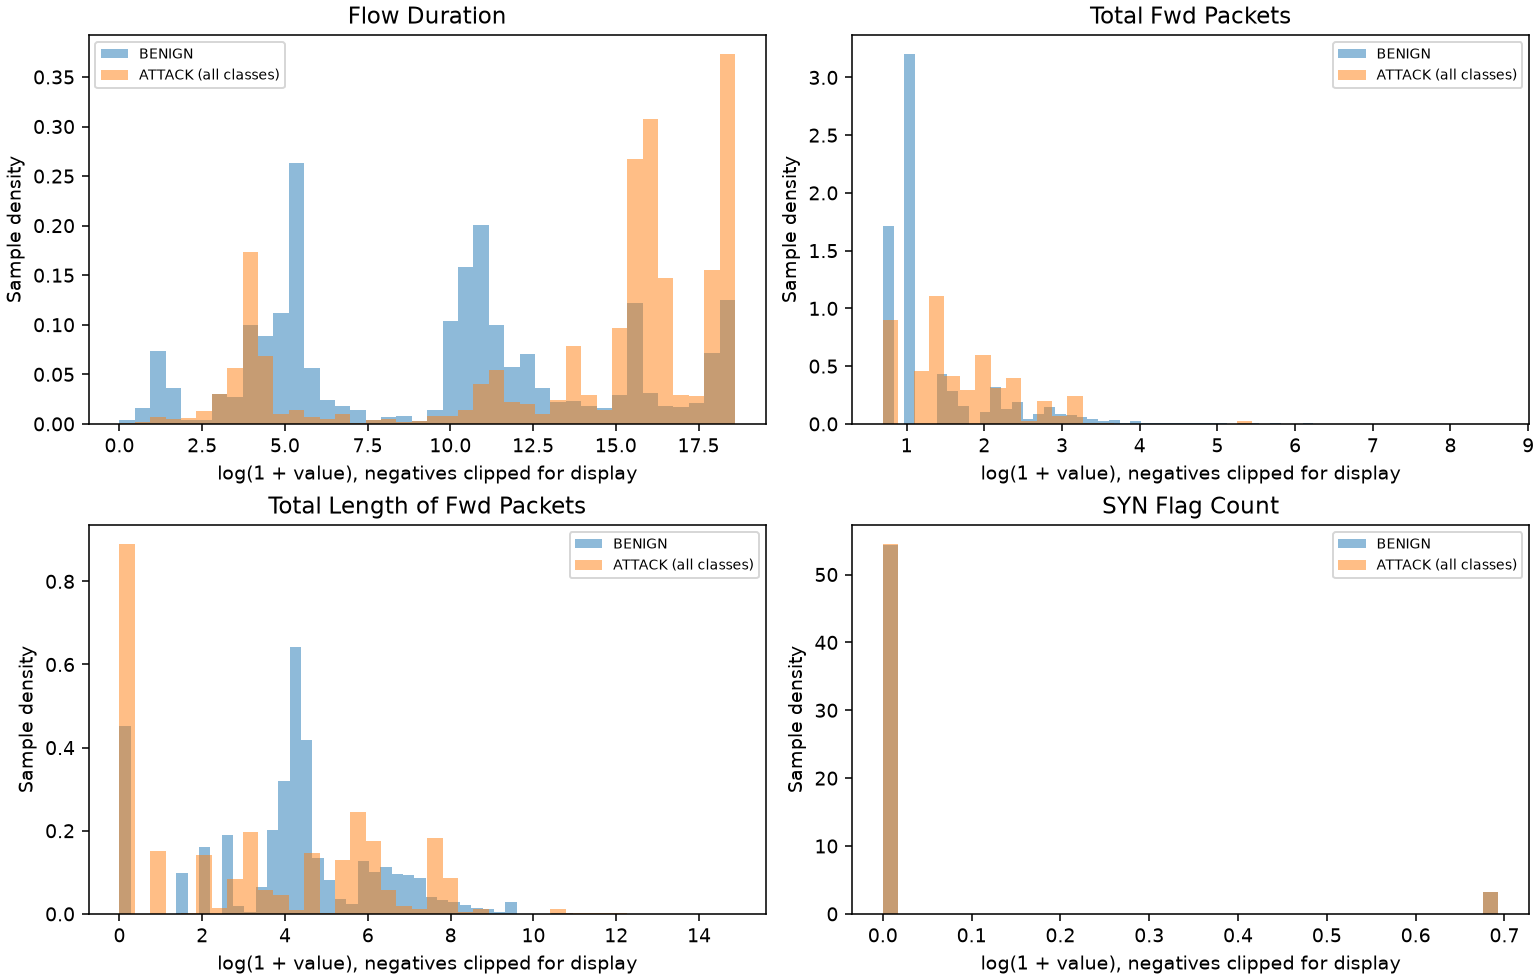

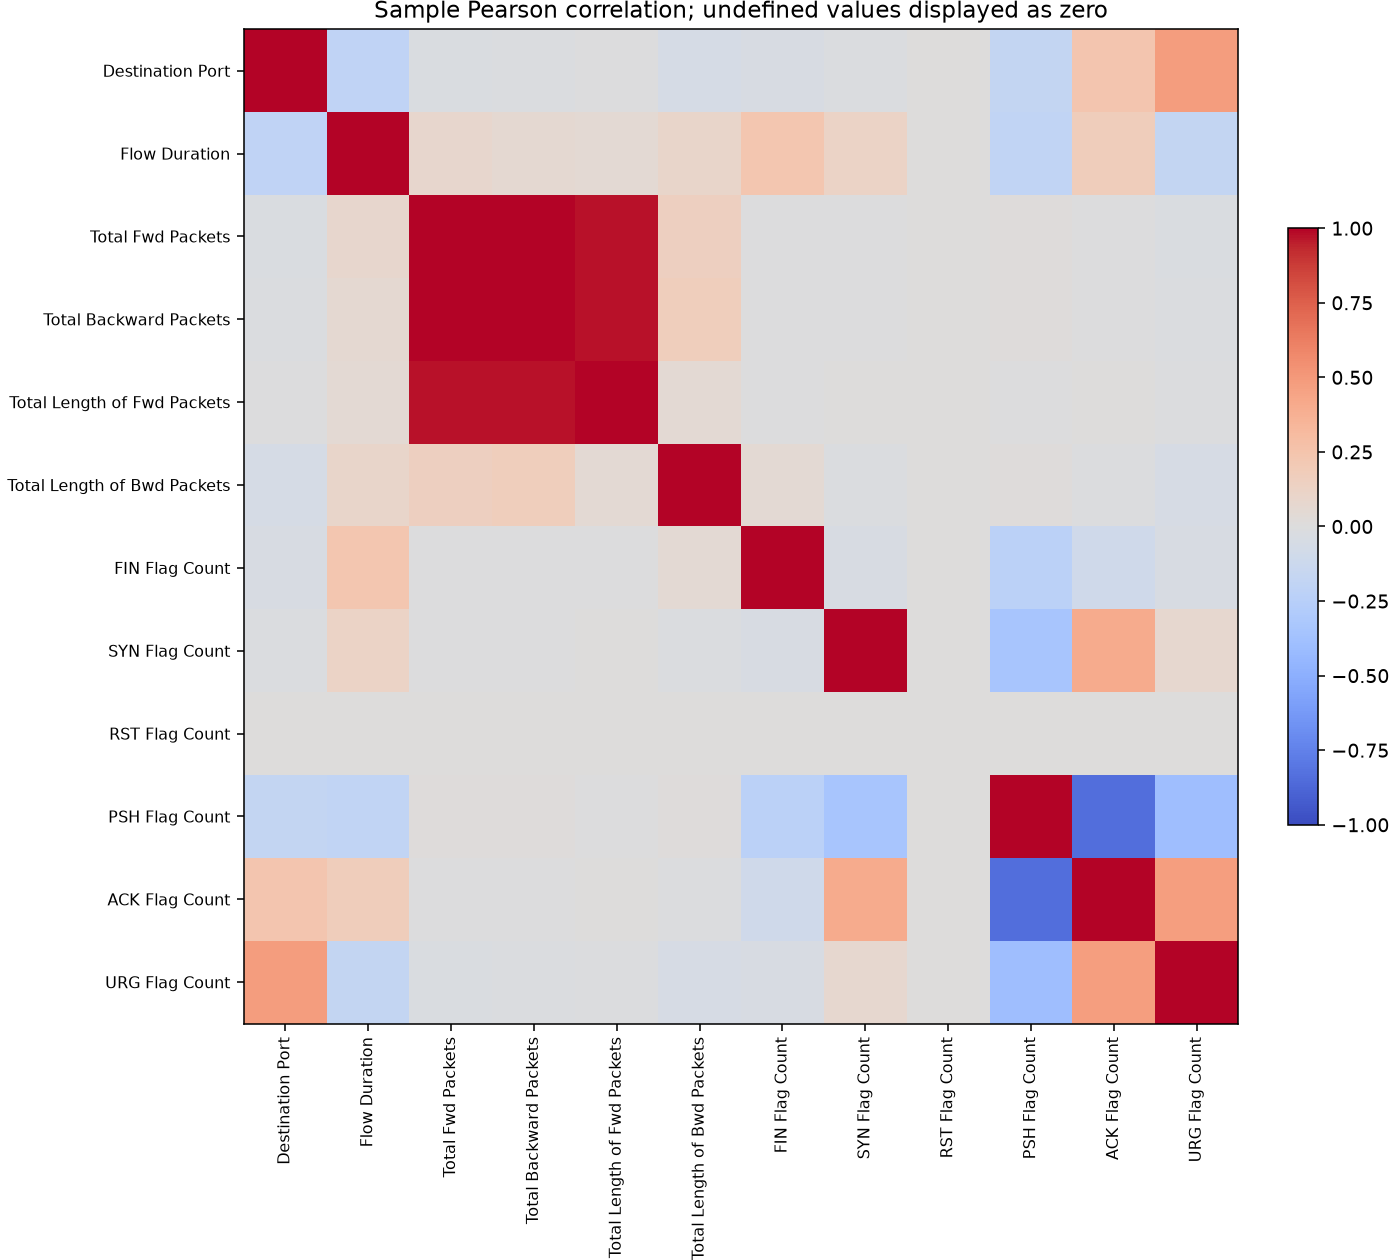

### InSDN

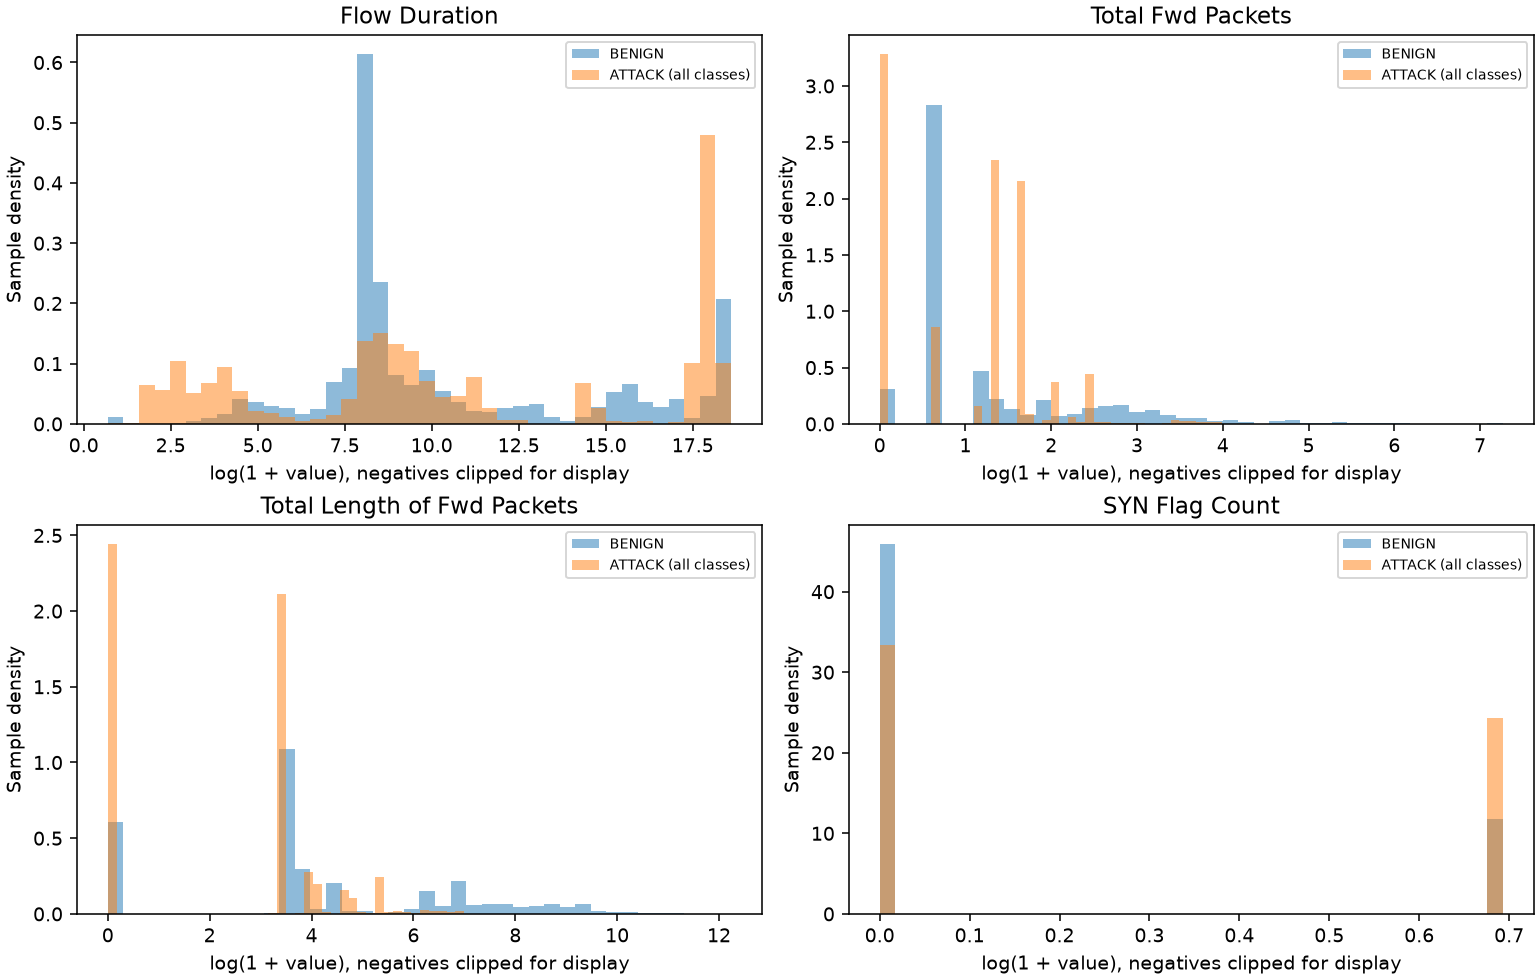

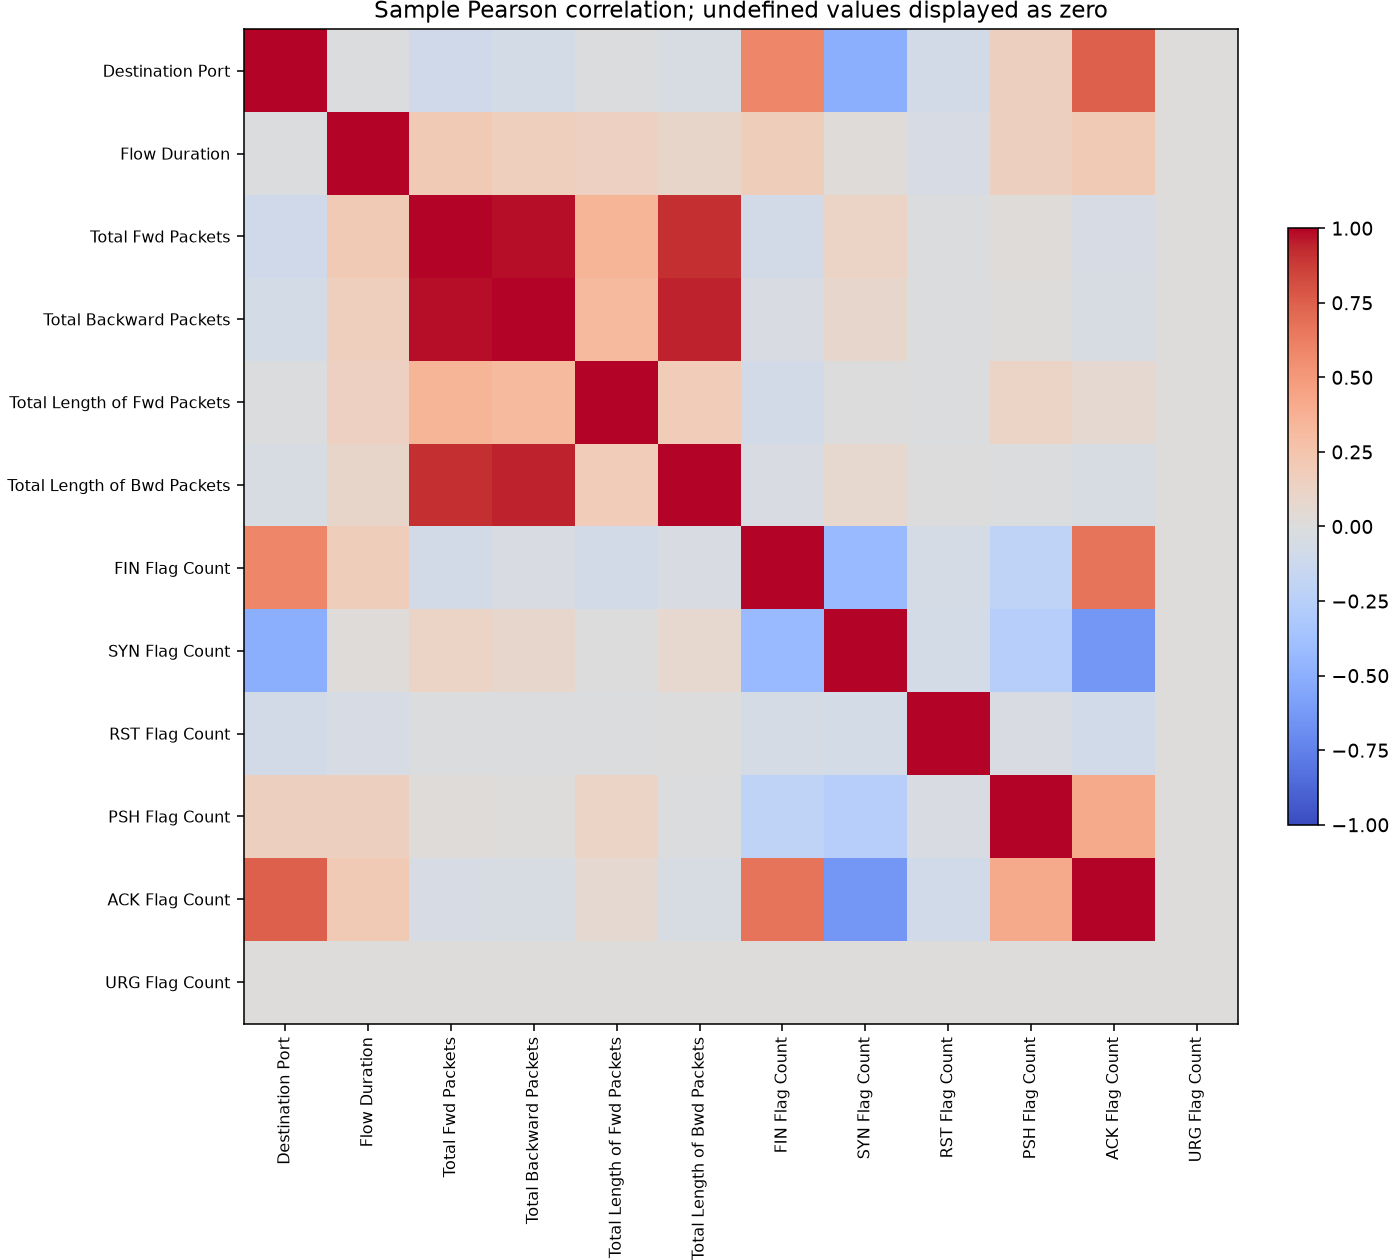

In [4]:
for name, folder in [('CIC-IDS2017', 'eda-cic'), ('InSDN', 'eda-insdn')]:
    display(Markdown(f'### {name}'))
    display(Image(filename=str(RUN / folder / 'feature_distributions.png')))
    display(Image(filename=str(RUN / folder / 'correlation.png')))


## 4. Baseline và Stacking: đầy đủ seed

M1 học CIC, M2 học InSDN, M3 học hai nguồn. Trong mỗi seed, M1/M3 có cùng Test CIC và M2/M3 có cùng Test InSDN. Test gộp được tính từ các hàng test nối lại. Các cột điểm là mean ± sample SD giữa seed, không phải khoảng tin cậy cho traffic thực tế.


In [5]:
all_scores = pd.read_csv(RUN / 'summary/all_seeds.csv')
keys = ['configuration', 'test_dataset', 'algorithm']
assert not all_scores.duplicated(keys + ['seed']).any(), 'Có model/test/seed bị tính lặp.'
seeds = sorted(all_scores.seed.unique().tolist())
print('Seeds:', seeds, '| Result rows:', len(all_scores))
summary = all_scores.groupby(keys)[['accuracy', 'macro_f1', 'benign_false_positive_rate',
                                    'attack_false_negative_rate']].agg(['mean', 'std'])
stack = summary.xs('stacking', level='algorithm')
table = pd.DataFrame(index=stack.index)
for metric, title in [('accuracy', 'Accuracy %'), ('macro_f1', 'Macro-F1 %'),
                      ('benign_false_positive_rate', 'FPR %'), ('attack_false_negative_rate', 'FNR %')]:
    table[title] = [f'{mean*100:.3f} ± {sd*100:.3f}'
                    for mean, sd in zip(stack[(metric, 'mean')], stack[(metric, 'std')])]
display(table)


Seeds: [7, 21, 42] | Result rows: 90


Accuracy %      Macro-F1 %          FPR %  \
configuration test_dataset                                                  
M1            cicids2017    99.329 ± 0.164  99.328 ± 0.164  0.779 ± 0.116   
M2            insdn         99.889 ± 0.077  99.876 ± 0.085  0.101 ± 0.000   
M3            cicids2017    99.330 ± 0.132  99.329 ± 0.132  0.813 ± 0.442   
              combined      99.577 ± 0.074  99.565 ± 0.075  0.490 ± 0.239   
              insdn         99.889 ± 0.038  99.876 ± 0.042  0.168 ± 0.058   

                                    FNR %  
configuration test_dataset                 
M1            cicids2017    0.554 ± 0.388  
M2            insdn         0.131 ± 0.226  
M3            cicids2017    0.517 ± 0.342  
              combined      0.332 ± 0.221  
              insdn         0.000 ± 0.000

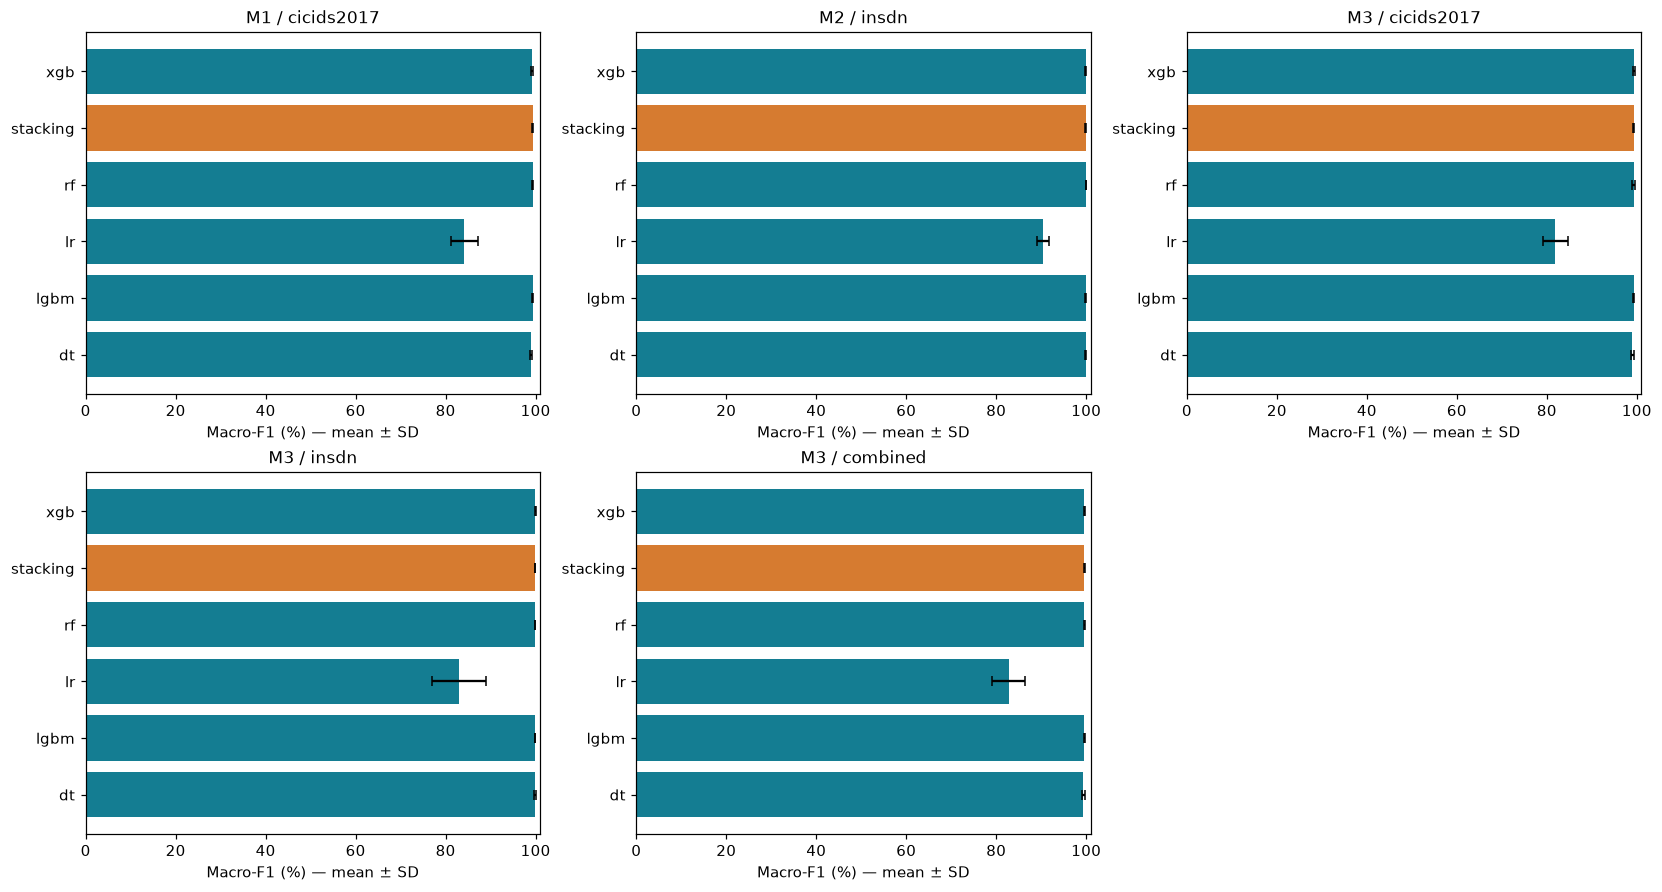

In [6]:
pairs = [('M1', 'cicids2017'), ('M2', 'insdn'), ('M3', 'cicids2017'), ('M3', 'insdn'), ('M3', 'combined')]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout='constrained')
for ax, pair in zip(axes.flat, pairs):
    data = summary.loc[pair].sort_index()
    colors = ['#d67b30' if name == 'stacking' else '#147d92' for name in data.index]
    ax.barh(data.index, data[('macro_f1', 'mean')]*100,
            xerr=data[('macro_f1', 'std')]*100, color=colors, capsize=3)
    ax.set(xlim=(0, 101), xlabel='Macro-F1 (%) — mean ± SD', title=f'{pair[0]} / {pair[1]}')
axes.flat[-1].axis('off')
plt.show()


## 5. So sánh Stacking với baseline trên từng test

“Baseline cao nhất” dưới đây chỉ mô tả **sau test**, không phải quy tắc chọn mô hình. Delta tính bằng điểm phần trăm; chênh lệch nhỏ và SD giữa ba seed chưa chứng minh ý nghĩa thống kê. Giữ mọi seed, kể cả khi Stacking thua.


In [7]:
delta_rows = []
for config, source in pairs:
    scores = summary.loc[(config, source)]
    baselines = scores.drop(index='stacking')[('macro_f1', 'mean')]
    best = baselines.idxmax()
    delta_rows.append({'configuration': config, 'test_dataset': source, 'baseline_descriptive': best,
                       'baseline_macro_f1_pct': baselines[best]*100,
                       'stacking_macro_f1_pct': scores.loc['stacking', ('macro_f1', 'mean')]*100,
                       'delta_percentage_points': (scores.loc['stacking', ('macro_f1', 'mean')]-baselines[best])*100})
display(pd.DataFrame(delta_rows).round(5))


,configuration,test_dataset,baseline_descriptive,baseline_macro_f1_pct,stacking_macro_f1_pct,delta_percentage_points
0,M1,cicids2017,rf,99.32859,99.32826,-0.00033
1,M2,insdn,rf,99.92477,99.87567,-0.04909
2,M3,cicids2017,rf,99.31102,99.32875,0.01773
3,M3,insdn,xgb,99.92581,99.87582,-0.05000
4,M3,combined,rf,99.57458,99.56478,-0.00980


## 6. Confusion matrix M3

Hàng là nhãn thật, cột là dự đoán; thứ tự nhãn lấy từ CSV, không tự giả định. Seed ở cell cấu hình chỉ thay đổi phần xem theo seed, không chọn seed tốt nhất để đưa vào bảng tổng hợp.


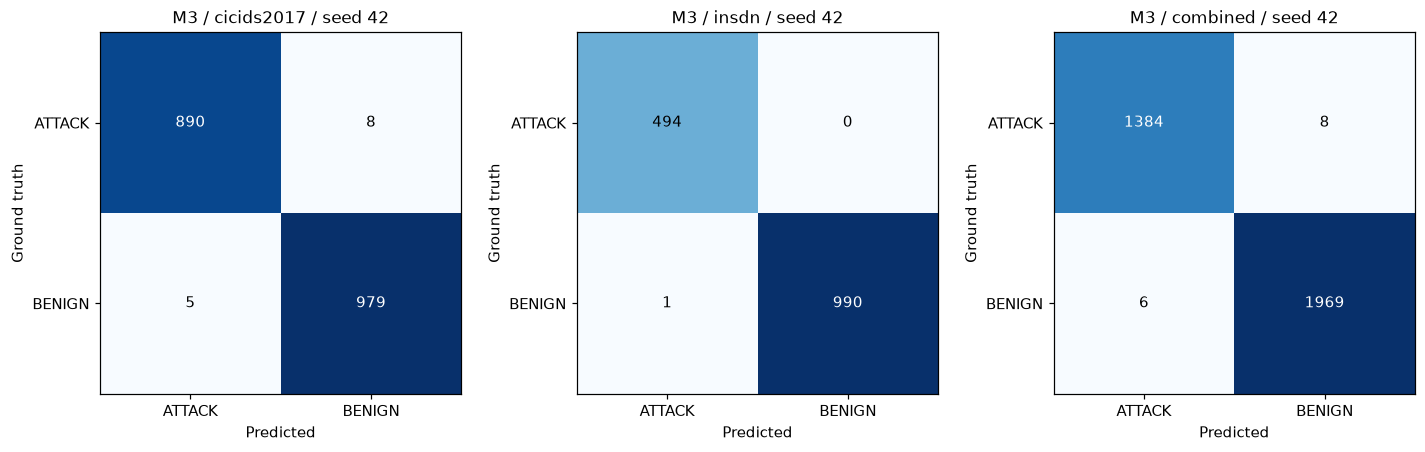

In [8]:
run_seed = RUN / f'three-models-seed{SEED}'
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout='constrained')
for ax, source in zip(axes, ['cicids2017', 'insdn', 'combined']):
    matrix = pd.read_csv(run_seed / 'M3' / source / 'confusion_stacking.csv', index_col=0)
    ax.imshow(matrix.to_numpy(), cmap='Blues')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(xlabel='Predicted', ylabel='Ground truth', title=f'M3 / {source} / seed {SEED}')
    for (i, j), value in np.ndenumerate(matrix.to_numpy()):
        ax.text(j, i, str(int(value)), ha='center', va='center',
                color='white' if value > matrix.to_numpy().max()/2 else 'black')
plt.show()


## 7. Phân loại đa lớp

Đây là thí nghiệm riêng, cap 2.000 theo lớp gốc và 60 cây; không so trực tiếp điểm đa lớp với điểm nhị phân. Bảng mỗi lớp có support để thấy lớp hiếm và các lớp bị loại.


### cicids2017: lớp bị loại {'Heartbleed': 11}

,precision,recall,f1-score,support
BENIGN,0.9698,0.9723,0.9711,397.0
Bot,0.9948,0.9871,0.9909,387.0
DDoS,1.0000,1.0000,1.0000,400.0
DoS GoldenEye,1.0000,0.9975,0.9987,400.0
DoS Hulk,0.9967,0.9902,0.9934,305.0
DoS Slowhttptest,0.9921,0.9921,0.9921,382.0
DoS slowloris,0.9892,0.9865,0.9878,370.0
FTP-Patator,0.9956,1.0000,0.9978,227.0
Infiltration,0.8750,1.0000,0.9333,7.0
PortScan,1.0000,0.9949,0.9975,396.0


### insdn: lớp bị loại {}

,precision,recall,f1-score,support
BENIGN,0.9975,0.9975,0.9975,398.0
BFA,0.7746,0.9322,0.8462,59.0
DDoS,1.0000,0.9750,0.9873,40.0
DoS,1.0000,0.9950,0.9975,199.0
Probe,0.9896,0.9573,0.9732,398.0
U2R,0.5000,1.0000,0.6667,3.0


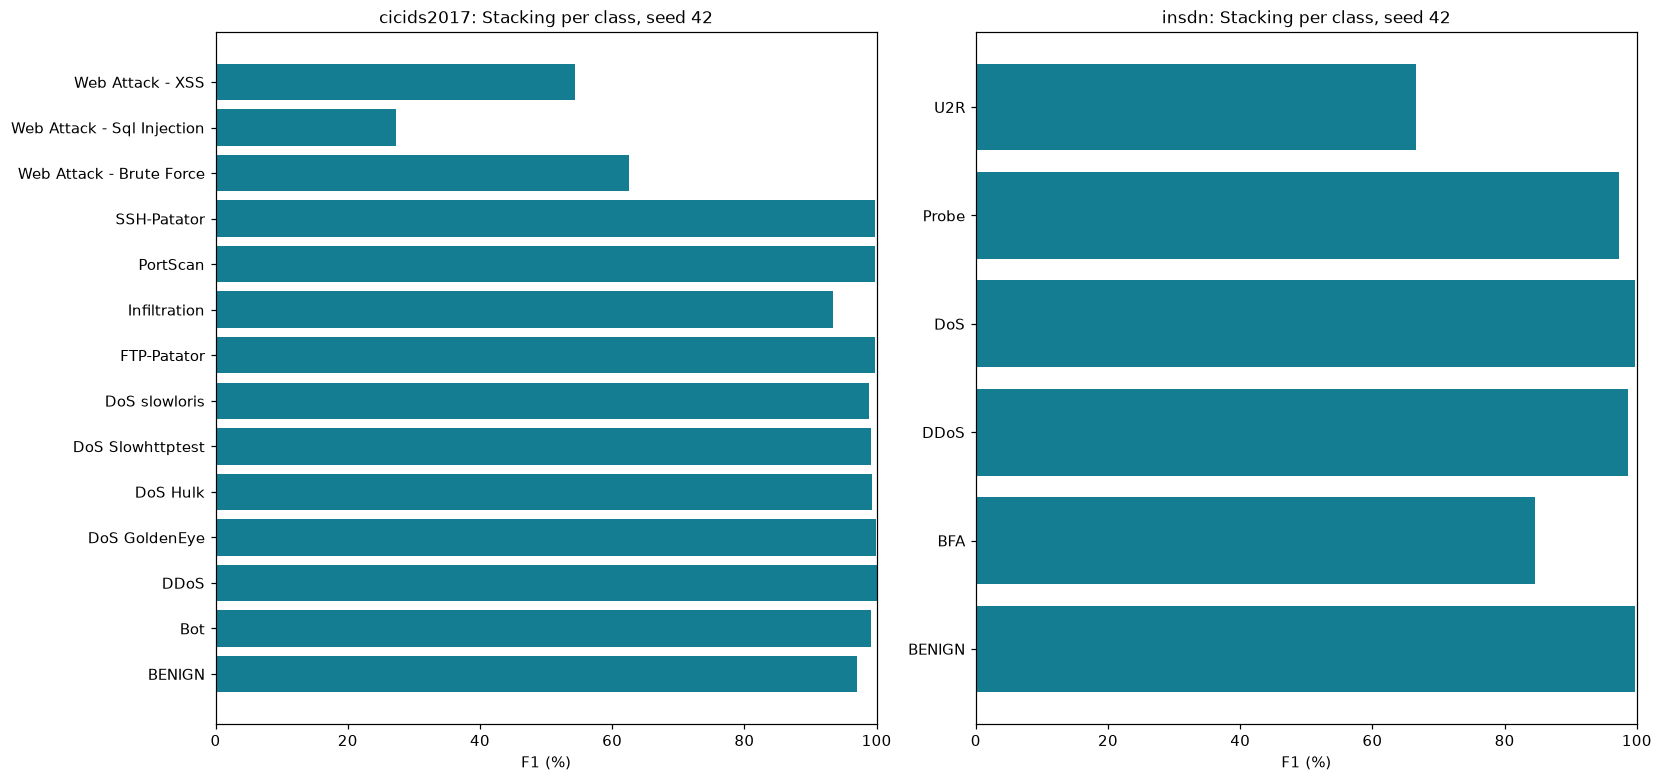

,dataset,model,accuracy,macro_f1
0,cicids2017,dt,0.94735,0.90532
1,cicids2017,rf,0.95042,0.90575
2,cicids2017,xgb,0.96243,0.92018
3,cicids2017,lgbm,0.95988,0.85803
4,cicids2017,lr,0.75313,0.67569
5,cicids2017,stacking,0.94838,0.87876
6,insdn,dt,0.97812,0.94513
7,insdn,rf,0.97903,0.91173
8,insdn,xgb,0.98177,0.91373
9,insdn,lgbm,0.97995,0.93471


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), layout='constrained')
multi_scores = []
for ax, source in zip(axes, ['cicids2017', 'insdn']):
    folder = RUN / f'multiclass-{source}-seed42'
    report = read_json(folder / 'report_stacking.json')['classification_report']
    protocol = read_json(folder / 'protocol.json')
    classes = {name: value for name, value in report.items()
               if isinstance(value, dict) and name not in ['macro avg', 'weighted avg']}
    per_class = pd.DataFrame(classes).T
    display(Markdown(f'### {source}: lớp bị loại {protocol["data"]["excluded_classes_below_minimum"]}'))
    display(per_class.round(4))
    ax.barh([str(x).replace('\ufffd', '-') for x in per_class.index], per_class['f1-score']*100, color='#147d92')
    ax.set(xlim=(0, 100), xlabel='F1 (%)', title=f'{source}: Stacking per class, seed 42')
    score = pd.read_csv(folder / 'comparison.csv')
    score.insert(0, 'dataset', source)
    multi_scores.append(score[['dataset', 'model', 'accuracy', 'macro_f1']])
plt.show()
display(pd.concat(multi_scores, ignore_index=True).round(5))


## 8. Gaussian anomaly: FPR và bỏ sót

Gaussian fit BENIGN train, ngưỡng từ BENIGN validation. Đặc biệt phải nhìn **FNR/Recall ATTACK**, không chỉ Accuracy hoặc FPR thấp. Test Gaussian host hiện chỉ có BENIGN: FNR/Recall ATTACK không xác định, không coi là 0 hoặc 100%.


,test_rows,attack_support,FPR,FNR,attack_recall
experiment,,,,,
CIC flow,1882,898,0.00813,0.90089,0.09911
InSDN flow,1485,494,0.00303,1.00000,0.00000
InSDN host,1488,0,0.00403,NaN,NaN


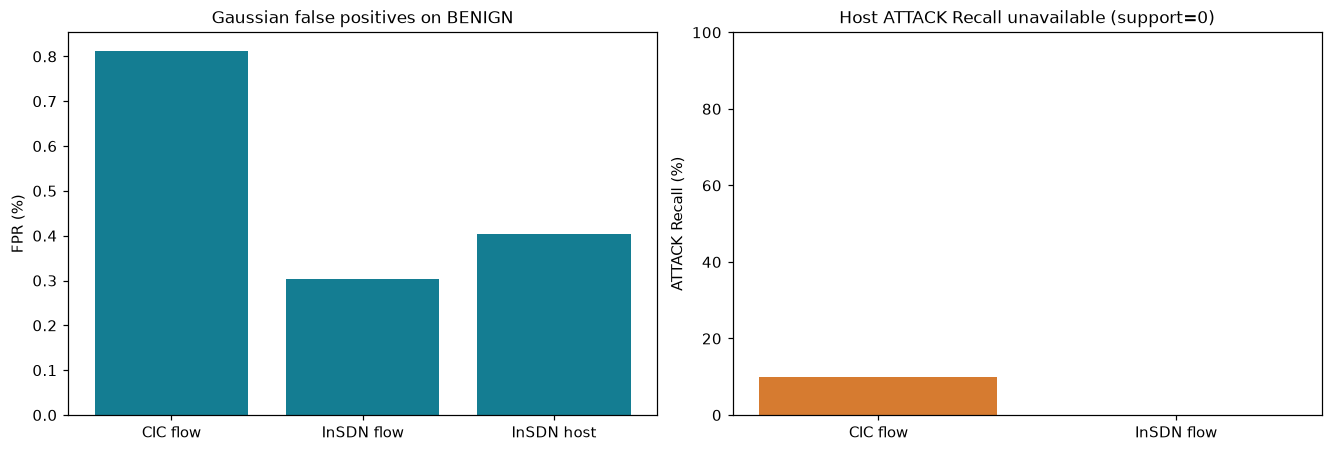

In [10]:
gaussian_rows = []
for source, folder in [('CIC flow', 'gaussian-cicids2017'), ('InSDN flow', 'gaussian-insdn'),
                       ('InSDN host', 'gaussian-insdn-host')]:
    report = read_json(RUN / folder / 'metrics.json')
    attack = report['classification_report']['ATTACK']
    gaussian_rows.append({'experiment': source, 'test_rows': report['evaluated_rows'],
                          'attack_support': int(attack['support']), 'FPR': report['false_positive_rate'],
                          'FNR': report['false_negative_rate'],
                          'attack_recall': attack['recall'] if attack['support'] > 0 else np.nan})
gaussian = pd.DataFrame(gaussian_rows).set_index('experiment')
display(gaussian.round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
axes[0].bar(gaussian.index, gaussian.FPR*100, color='#147d92')
axes[0].set(ylabel='FPR (%)', title='Gaussian false positives on BENIGN')
known_attack = gaussian.loc[gaussian.attack_support > 0]
axes[1].bar(known_attack.index, known_attack.attack_recall*100, color='#d67b30')
axes[1].set(ylim=(0, 100), ylabel='ATTACK Recall (%)', title='Host ATTACK Recall unavailable (support=0)')
plt.show()


## 9. Host và graph

GraphML giữ toàn bộ node/cạnh; hình SVG chỉ hiện 40 host nhiều flow nhất và gộp thời gian/hướng để nhìn tổng quan. Fan-in/fan-out là ứng viên cấu trúc, không phải bằng chứng botnet/C2. Host/window ATTACK bao gồm cả nạn nhân, không đồng nghĩa host nhiễm mã độc.


,flow_rows_used,invalid_time_rows_removed,host_windows,graph_nodes,directed_edges,candidate_host_windows
0,205159,8,88072,74615,75528,584


,host_windows_by_label
ATTACK,73640
BENIGN,14432


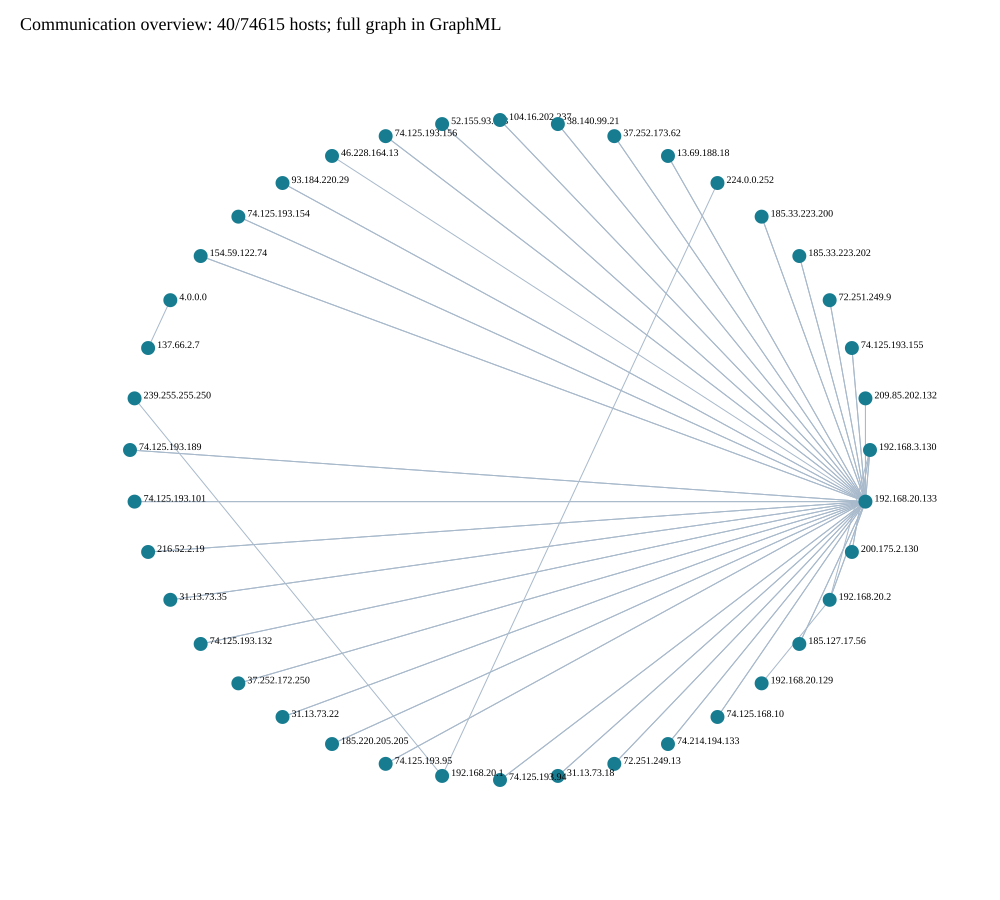

In [11]:
host_info = read_json(RUN / 'insdn-hosts/protocol.json')
graph_info = read_json(RUN / 'insdn-graph/summary.json')
display(pd.DataFrame([{'flow_rows_used': host_info['flows'],
                       'invalid_time_rows_removed': host_info['invalid_time_rows_removed'],
                       'host_windows': host_info['host_windows'], 'graph_nodes': graph_info['nodes'],
                       'directed_edges': graph_info['directed_edges'],
                       'candidate_host_windows': graph_info['candidate_host_windows']}]))
display(pd.Series(host_info['label_counts'], name='host_windows_by_label').to_frame())
display(SVG(filename=str(RUN / 'insdn-graph/overview.svg')))


## 10. Kiểm tra protocol và model đã lưu

Đối chiếu hash để xác nhận cùng các hàng test; kiểm tra marker hoàn tất và sự tồn tại của model. Cell này không load `.joblib` và không coi “file tồn tại” là bằng chứng độ chính xác realtime.


In [12]:
protocol_rows = []
for seed in seeds:
    folder = RUN / f'three-models-seed{seed}'
    m1, m2, m3 = [read_json(folder / name / 'protocol.json') for name in ['M1', 'M2', 'M3']]
    done = read_json(folder / 'completed.json')
    cic_equal = m1['split_feature_sha256']['cicids2017'] == m3['split_feature_sha256']['cicids2017']
    insdn_equal = m2['split_feature_sha256']['insdn'] == m3['split_feature_sha256']['insdn']
    models_exist = all((folder / name / 'models/stacking_ids.joblib').is_file() for name in ['M1', 'M2', 'M3'])
    assert cic_equal and insdn_equal and done['result_rows'] == 30 and models_exist
    protocol_rows.append({'seed': seed, 'same_test_CIC': cic_equal, 'same_test_InSDN': insdn_equal,
                          'completed_rows': done['result_rows'], 'three_models_exist': models_exist})
display(pd.DataFrame(protocol_rows))


,seed,same_test_CIC,same_test_InSDN,completed_rows,three_models_exist
0,7,True,True,30,True
1,21,True,True,30,True
2,42,True,True,30,True


## 11. Accuracy từ nhãn thật khi nạp lại M3

Đọc kết quả `evaluate_model.py` trên toàn bộ hai test của **seed 42**, không train lại. Đây là so với Label, khác Prediction match so với dự đoán đã lưu. Số liệu là cùng test đã có, chưa phải holdout độc lập mới. Errors là mẫu sai để phân tích, không dùng chọn lại model trên chính test này.

In [13]:
evaluation_rows = []
for source in ['cicids2017', 'insdn']:
    folder = RUN / f'windows-evaluation-m3-{source}'
    if not (folder / 'metrics.json').exists():
        display(Markdown(f'Chưa có đánh giá lại cho {source} trong RUN này.'))
        continue
    scores = read_json(folder / 'metrics.json')
    mistakes = pd.read_csv(folder / 'errors.csv')
    evaluation_rows.append({'test': source, 'rows': scores['rows'], 'errors': len(mistakes),
                            **{key: scores[key] * 100 for key in ['accuracy', 'macro_f1', 'benign_false_positive_rate', 'attack_false_negative_rate']}})
    display(Markdown(f'**{source}: tối đa 10 mẫu dự đoán sai**'))
    display(mistakes[['GroundTruth', 'Prediction', 'Destination Port', 'Flow Duration', 'SYN Flag Count']].head(10))
if evaluation_rows:
    display(Markdown('**Các cột metric dưới đây có đơn vị %.**'))
    display(pd.DataFrame(evaluation_rows).round(4))

**cicids2017: tối đa 10 mẫu dự đoán sai**

,GroundTruth,Prediction,Destination Port,Flow Duration,SYN Flag Count
0,ATTACK,BENIGN,80.0,33988210.0,0.0
1,BENIGN,ATTACK,80.0,8999281.0,0.0
2,ATTACK,BENIGN,80.0,5784839.0,0.0
3,ATTACK,BENIGN,80.0,5921092.0,0.0
4,ATTACK,BENIGN,80.0,80.0,0.0
5,BENIGN,ATTACK,143.0,28.0,0.0
6,BENIGN,ATTACK,8080.0,997287.0,0.0
7,BENIGN,ATTACK,80.0,61978275.0,0.0
8,ATTACK,BENIGN,8080.0,93817.0,0.0
9,ATTACK,BENIGN,80.0,5870237.0,0.0


**insdn: tối đa 10 mẫu dự đoán sai**

,GroundTruth,Prediction,Destination Port,Flow Duration,SYN Flag Count
0,BENIGN,ATTACK,443.0,4594.0,1.0


**Các cột metric dưới đây có đơn vị %.**

,test,rows,errors,accuracy,macro_f1,benign_false_positive_rate,attack_false_negative_rate
0,cicids2017,1882,13,99.3092,99.3077,0.5081,0.8909
1,insdn,1485,1,99.9327,99.9242,0.1009,0.0000


## 12. Ablation giữ cùng cỡ mẫu

Mỗi seed có cùng số hàng từng lớp trong train/validation giữa CIC_matched, InSDN_matched và Mixed_matched. Mixed lấy 50% mỗi nguồn; test giữ nguyên. Bảng/heatmap dùng mean Macro-F1 của đủ ba seed. Cấu hình hỗn hợp đã thấy hai miền trong train; kết quả không chứng minh tổng quát sang miền mới. Đây là phân tích bổ sung trên test đã được xem trước.

mean    std
configuration test_dataset               
CIC_matched   cicids2017    99.275  0.171
              combined      84.598  1.354
              insdn         50.041  7.643
InSDN_matched cicids2017    41.553  7.022
              combined      69.514  2.982
              insdn         99.900  0.043
Mixed_matched cicids2017    99.099  0.276
              combined      99.422  0.161
              insdn         99.851  0.073

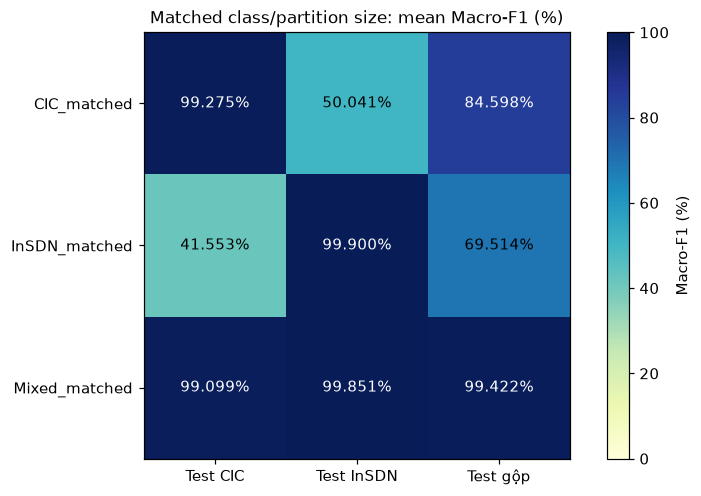

,seed,train_ATTACK,train_BENIGN,validation_ATTACK,validation_BENIGN
0,7,1528,2946,508,982
1,21,1528,2952,510,984
2,42,1482,2948,494,984


In [14]:
ablation_folder = RUN / 'size-ablation'
if (ablation_folder / 'completed.json').exists():
    ablation = pd.read_csv(ablation_folder / 'all_seeds.csv')
    assert not ablation.duplicated(['configuration', 'test_dataset', 'algorithm', 'seed']).any()
    assert len(ablation) == read_json(ablation_folder / 'completed.json')['result_rows']
    stack_ablation = ablation.loc[ablation.algorithm.eq('stacking')]
    ablation_summary = stack_ablation.groupby(['configuration', 'test_dataset']).macro_f1.agg(['mean', 'std']) * 100
    display(ablation_summary.round(3))
    matrix = ablation_summary['mean'].unstack('test_dataset').reindex(
        index=['CIC_matched', 'InSDN_matched', 'Mixed_matched'], columns=['cicids2017', 'insdn', 'combined'])
    fig, ax = plt.subplots(figsize=(8, 4.4), layout='constrained')
    chart = ax.imshow(matrix, cmap='YlGnBu', vmin=0, vmax=100)
    ax.set_xticks(range(3), ['Test CIC', 'Test InSDN', 'Test gộp'])
    ax.set_yticks(range(3), matrix.index)
    ax.set_title('Matched class/partition size: mean Macro-F1 (%)')
    for row in range(3):
        for col in range(3):
            value = matrix.iloc[row, col]
            ax.text(col, row, f'{value:.3f}%', ha='center', va='center', color='white' if value > 70 else 'black')
    fig.colorbar(chart, ax=ax, label='Macro-F1 (%)')
    plt.show()
    budgets = []
    for seed in sorted(ablation.seed.unique()):
        protocol = read_json(ablation_folder / f'seed{seed}/ablation_protocol.json')
        budgets.append({'seed': seed, **{f'{part}_{label}': count for part, labels in protocol['budgets'].items() for label, count in labels.items()}})
    display(pd.DataFrame(budgets))
else:
    display(Markdown('Chưa có ablation cùng cỡ mẫu trong RUN này.'))

## 13. Beaconing: ứng viên định kỳ

Chỉ phân tích flow chưa lấy mẫu. Nhóm theo endpoint/cổng/protocol; timestamp trùng được đếm và khử. Ngưỡng mặc định: ít nhất 6 thời điểm khác nhau, span ≥60 giây, mean interval ≥1 giây, CV ≤0,1. CV thấp không chứng minh C2. Trong InSDN local, các flow của ba ứng viên mang nhãn Normal; timestamp thô và polling hợp pháp có thể tạo chu kỳ.

In [15]:
beacon_folder = RUN / 'beaconing-insdn'
if (beacon_folder / 'summary.json').exists():
    beacon_info = read_json(beacon_folder / 'summary.json')
    display(pd.DataFrame([{key: beacon_info[key] for key in ['source_rows', 'input_flows', 'pairs', 'candidate_pairs', 'duplicate_starts', 'invalid_time_rows_removed']}]))
    display(pd.Series(beacon_info['unsupported_protocol_rows'], name='excluded_protocol_rows').to_frame())
    display(pd.read_csv(beacon_folder / 'candidates.csv'))
    display(Markdown('**Đây là ứng viên định kỳ, chưa có ground truth C2 hoặc độ chính xác botnet.**'))
else:
    display(Markdown('Chưa có kết quả beaconing trong RUN này.'))

,source_rows,input_flows,pairs,candidate_pairs,duplicate_starts,invalid_time_rows_removed
0,205167,131744,37443,3,61513,8


,excluded_protocol_rows
0,73415


,src_ip,dst_ip,dst_port,protocol,flow_count,unique_starts,duplicate_starts,span_seconds,mean_interval_seconds,interval_std_seconds,interval_cv,candidate
0,192.168.20.133,209.85.203.136,443,TCP,9,9,0,960.0,120.0,0.0,0.0,True
1,192.168.20.133,52.114.74.44,443,TCP,7,7,0,720.0,120.0,0.0,0.0,True
2,192.168.20.133,52.94.220.16,443,TCP,7,7,0,720.0,120.0,0.0,0.0,True


**Đây là ứng viên định kỳ, chưa có ground truth C2 hoặc độ chính xác botnet.**

## 14. Trạng thái capture Windows

Trạng thái thất bại/thiếu quyền được trình bày riêng; không thay bằng metrics từ PCAP tổng hợp. Xem `docs/WINDOWS_VALIDATION.md` để chạy lab với quyền capture phù hợp và scope BPF hẹp.

In [16]:
live_folder = RUN / 'windows-localhost-benign'
if (live_folder / 'protocol.json').exists():
    display(pd.Series(read_json(live_folder / 'protocol.json'), name='Windows capture status').to_frame())
    if (live_folder / 'live/metrics.json').exists():
        display(pd.Series(read_json(live_folder / 'live/metrics.json'), name='Live metrics').to_frame())
else:
    display(Markdown('Chưa có phiên capture Windows trong RUN này.'))

,Windows capture status
status,blocked_capture_permission
platform,Windows
interface,\Device\NPF_Loopback
scope,Planned benign HTTP to 127.0.0.1 on a process-...
http_requests,0
captured_packets,0
metrics_available,False
reason,Npcap Admin-only Mode denied capture in this n...


## 15. Đa lớp: tìm kiếm meta learner qua ba seed

12 cấu hình meta/base được chọn bằng train OOF và validation, không chọn bằng test. Giữ nguyên ngân sách baseline. Bảng này là protocol có meta-search, khác phần đa lớp seed 42 cố định ở mục 7. Báo đủ ba seed kể cả khi ES thấp hơn baseline. Test đã được xem trong quá trình phát triển nên kết quả chưa phải xác nhận độc lập mới.

Xem `notebooks/training.ipynb` để huấn luyện theo từng bước; mặc định chỉ đọc artifact.

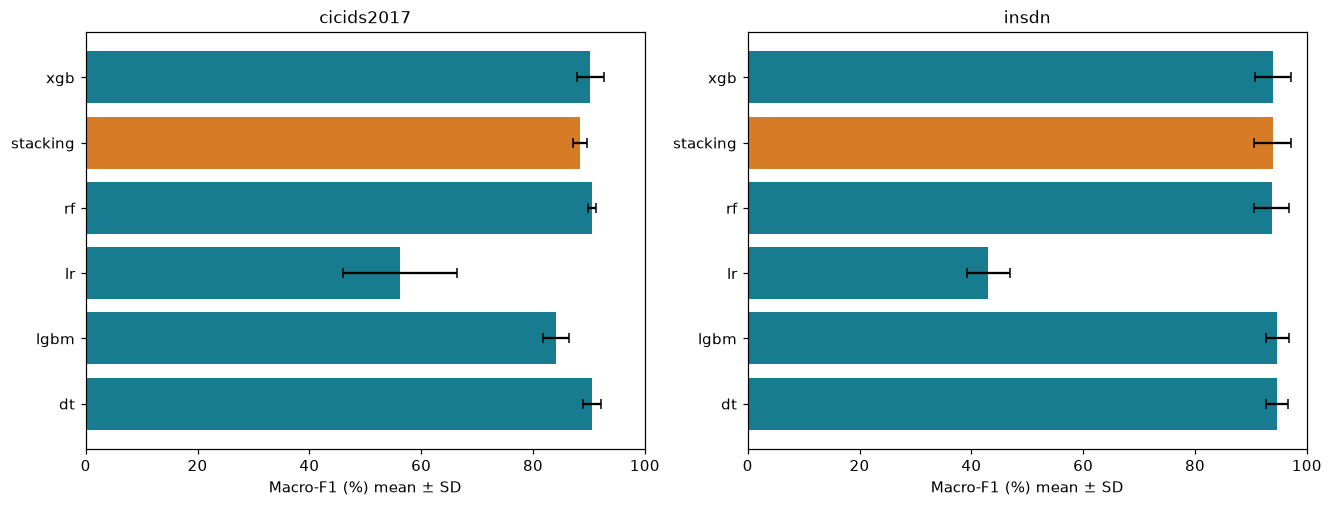

,model,mean,std,dataset
0,dt,90.539,1.615,cicids2017
1,lgbm,84.096,2.350,cicids2017
2,lr,56.256,10.209,cicids2017
3,rf,90.606,0.684,cicids2017
4,stacking,88.404,1.310,cicids2017
5,xgb,90.272,2.380,cicids2017
6,dt,94.610,1.948,insdn
7,lgbm,94.734,2.069,insdn
8,lr,43.038,3.887,insdn
9,rf,93.735,3.101,insdn


**ES chưa vượt baseline ở protocol này. Không lựa seed tốt nhất để thay bảng tổng hợp.**

In [17]:
meta_tables = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
for ax, source in zip(axes, ['cicids2017', 'insdn']):
    folder = RUN / f'multiclass-search-{source}-summary'
    if not (folder / 'all_seeds.csv').exists():
        ax.set_visible(False)
        continue
    data = pd.read_csv(folder / 'all_seeds.csv')
    assert sorted(data.seed.unique()) == [7, 21, 42]
    scores = data.groupby('model').macro_f1.agg(['mean', 'std']) * 100
    ax.barh(scores.index, scores['mean'], xerr=scores['std'], color=['#d77c26' if name == 'stacking' else '#187c91' for name in scores.index], capsize=3)
    ax.set(xlim=(0, 100), xlabel='Macro-F1 (%) mean ± SD', title=source)
    meta_tables.append(scores.assign(dataset=source).reset_index())
plt.show()
if meta_tables:
    display(pd.concat(meta_tables, ignore_index=True).round(3))
display(Markdown('**ES chưa vượt baseline ở protocol này. Không lựa seed tốt nhất để thay bảng tổng hợp.**'))

## Giới hạn và cách chạy lại

- Output trong notebook là snapshot của `RUN`; đổi artifact hoặc code không tự cập nhật output. Chạy lại từ đầu và Save để đồng bộ.
- Class cap/random split chưa đại diện cho traffic tự nhiên; SD giữa seed chưa phải khoảng tin cậy.
- Gaussian flow đang bỏ sót nhiều attack; graph chưa có ground truth botnet; chưa có số đo Kali thật hoặc feature parity của hai extractor độc lập.
- Để huấn luyện mới, chạy `src/train_all.py --combined` từ terminal với `--out` mới, hoặc các lệnh trong `docs/THREE_MODELS.md` và `docs/EXTENSIONS.md`. Sau đó đổi `RUN` ở cell đầu. Không nhân bản logic train vào notebook.
- Phân loại đa lớp trong notebook hiện đọc hai lượt seed 42 đã lưu, độc lập với biến `SEED` dùng cho confusion matrix nhị phân.

Xem `docs/CURRENT_RESULTS.md`, `docs/REPORT.md`, `docs/COMPLETION_REVIEW.md` để viết kết luận đúng với bằng chứng.
